### Data insertion and cleaning


In [1]:
from io import StringIO
import pandas as pd
import requests
import json, re, time
from pathlib import Path
from rapidfuzz import fuzz, process
from tqdm import tqdm
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter



def requestConstituents(url, table_id):
    response = requests.get(
        url,
        headers={"User-Agent": "AAIS student project"},
        timeout=30,
    )
    response.raise_for_status()

    tables = pd.read_html(
        StringIO(response.text),
        attrs={"id": table_id},
        flavor="lxml",
    )
    df = tables[0]
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [
            "_".join(dict.fromkeys(str(level) for level in column if level))
            for column in df.columns
        ]
    df.columns = df.columns.str.lower().str.replace(" ", "_")
 
    
    return df

constituents_df = (
    requestConstituents(
        "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
        "constituents",
    )
)
history_df = (
    requestConstituents(
        "https://en.wikipedia.org/wiki/Historical_components_of_the_S&P_500",
          "changes",
          )
)
constituents_df["yahoo_symbol"] = constituents_df["symbol"].str.replace(".", "-", regex=False)

history_df['yahoo_added_ticker'] = history_df['added_ticker'].str.replace(".", "-", regex=False)
history_df['yahoo_removed_ticker'] = history_df['removed_ticker'].str.replace(".", "-", regex=False)


In [2]:
def canonical_ticker(ticker, date, renames = {}):
    for _ in range(5): 
        rule = renames.get(ticker)
        if rule is None:
            break
        new, cutoff = rule
        if cutoff is not None and date >= pd.Timestamp(cutoff):
            break
        ticker = new
    return ticker


def prepare_events_df(history_df):
    df = history_df.copy()
    df["date"] = pd.to_datetime(df["effective_date"], format="%B %d, %Y", errors="coerce")

    added = df[["date", "yahoo_added_ticker"]].rename(columns={"yahoo_added_ticker": "ticker"}).assign(action="add")
    removed = df[["date", "yahoo_removed_ticker"]].rename(columns={"yahoo_removed_ticker": "ticker"}).assign(action="remove")

    events_df = pd.concat([added, removed], ignore_index=True)
    events_df["ticker"] = events_df["ticker"].astype("string").str.strip()
    events_df = events_df.dropna(subset=["date", "ticker"])
    events_df = events_df[events_df["ticker"] != ""]

    
    events_df["ticker"] = [canonical_ticker(t, d) for t, d in zip(events_df["ticker"], events_df["date"])]

   
    events_df["order"] = events_df["action"].map({"remove": 0, "add": 1})
    events_df = events_df.sort_values(["date", "order"], kind="stable")
    return events_df.drop(columns="order").reset_index(drop=True)


def members_on(intervals, date):
    d = pd.Timestamp(date)
    started = intervals["start"].isna() | (intervals["start"] <= d)
    not_ended = intervals["end"].isna() | (intervals["end"] > d)
    return sorted(intervals.loc[started & not_ended, "ticker"])


In [3]:
events_df = prepare_events_df(history_df)
intervals = []

for event in events_df.itertuples():
    if event.action == "add":
        intervals.append((event.ticker, event.date, None))
    else:
        for i in range(len(intervals)):
            if intervals[i][0] == event.ticker and intervals[i][2] is None:
                intervals[i] = (intervals[i][0], intervals[i][1], event.date)
                break
        else:
            intervals.append((event.ticker, None, event.date))

constituents_df["date_added"] = pd.to_datetime(constituents_df["date_added"], errors="coerce")

open_tickers = {t for t, _, end in intervals if end is None}
orphans = []  
for row in constituents_df.itertuples():
    if row.yahoo_symbol not in open_tickers:
        orphans.append(row.yahoo_symbol)
        intervals.append((row.yahoo_symbol, row.date_added, None))


In [4]:
iv = pd.DataFrame(intervals, columns=["ticker", "start", "end"])

current = set(constituents_df["yahoo_symbol"])
open_mask = iv["end"].isna()
phantoms = sorted(set(iv.loc[open_mask, "ticker"]) - current)


ph = iv[open_mask & iv["ticker"].isin(phantoms)]
orph = constituents_df.loc[constituents_df["yahoo_symbol"].isin(orphans), ["yahoo_symbol", "security", "date_added"]]



iv = iv[~(open_mask & iv["ticker"].isin(phantoms))].reset_index(drop=True)


In [5]:
early, far = pd.Timestamp("1900-01-01"), pd.Timestamp("2100-01-01")
x = iv.assign(s=iv["start"].fillna(early), e=iv["end"].fillna(far)).sort_values(["ticker", "s"])


dates = pd.date_range("2005-01-01", pd.Timestamp.today(), freq="MS")
counts = pd.Series([len(members_on(iv, d)) for d in dates], index=dates)


In [6]:
SEC_HEADERS = {"User-Agent": "Name Surname email@example.com"}

DATA_DIR = Path("data")
(DATA_DIR / "companyfacts").mkdir(parents=True, exist_ok=True)

START, END = "2010-12-31", "2026-09-30"  
PRICE_START = "2009-06-01"               


def to_long(wide, name):
    return (wide.rename_axis(index="date", columns="ticker")
                .reset_index()
                .melt(id_vars="date", var_name="ticker", value_name=name))


def get_companyfacts(cik):
    path = DATA_DIR / "companyfacts" / f"CIK{int(cik):010d}.json"
    if path.exists():
        return json.loads(path.read_text())
    url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{int(cik):010d}.json"
    r = requests.get(url, headers=SEC_HEADERS, timeout=30)
    time.sleep(0.15)  
    if r.status_code not in (200, 404):
        r.raise_for_status()
    data = r.json() if r.status_code == 200 else {}
    path.write_text(json.dumps(data))
    return data

In [7]:
months = pd.date_range(START, END, freq="ME")
panel = pd.DataFrame(
    [(d, t) for d in months for t in members_on(iv, d)],
    columns=["date", "ticker"],
)

### Insertion of the cik number for tickets using information from Wikipedia, and manual insertion


In [8]:
h = history_df.copy()
h["date"] = pd.to_datetime(h["effective_date"], format="%B %d, %Y", errors="coerce")
h = h.dropna(subset=["date"]).sort_values("date")  

names = {}
for col_t, col_n in [("yahoo_added_ticker", "added_security"), ("yahoo_removed_ticker", "removed_security")]:
    for t, n, d in zip(h[col_t], h[col_n], h["date"]):
        if pd.notna(t) and pd.notna(n):
            names[canonical_ticker(str(t).strip(), d)] = n
names.update(dict(zip(constituents_df["yahoo_symbol"], constituents_df["security"])))

tickers_df = pd.DataFrame({"ticker": sorted(panel["ticker"].unique())})
tickers_df["name"] = tickers_df["ticker"].map(names)

SUFFIXES = r"\b(INC|INCORPORATED|CORP|CORPORATION|CO|COMPANY|LTD|LIMITED|PLC|LLC|LP|THE|NV|SA|AG)\b"

def norm_name(s):
    if pd.isna(s):
        return ""
    s = str(s).upper().replace("&", " AND ")
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    s = re.sub(SUFFIXES, " ", s)
    return " ".join(s.split())

In [9]:
tickers_df["cik"] = tickers_df["ticker"].map(
    dict(zip(constituents_df["yahoo_symbol"], pd.to_numeric(constituents_df["cik"], errors="coerce")))
)
tickers_df["cik_source"] = np.where(tickers_df["cik"].notna(), "wiki", None)


r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS, timeout=30)
r.raise_for_status()
sec_t = pd.DataFrame(r.json().values()).rename(columns={"cik_str": "sec_cik", "title": "sec_name"})
sec_t["ticker"] = sec_t["ticker"].str.replace(".", "-", regex=False)

cand = tickers_df[tickers_df["cik"].isna()].merge(sec_t, on="ticker", how="inner")
cand["score"] = [fuzz.token_sort_ratio(norm_name(a), norm_name(b)) for a, b in zip(cand["name"], cand["sec_name"])]
good = cand[cand["score"] >= 80].set_index("ticker")["sec_cik"]
tickers_df.loc[tickers_df["ticker"].isin(good.index), "cik_source"] = "sec_tickers"
tickers_df["cik"] = tickers_df["cik"].fillna(tickers_df["ticker"].map(good))



In [10]:
path = DATA_DIR / "cik-lookup-data.txt"
if not path.exists():
    r = requests.get("https://www.sec.gov/Archives/edgar/cik-lookup-data.txt", headers=SEC_HEADERS, timeout=300)
    r.raise_for_status()
    path.write_bytes(r.content)

rows = []
with open(path, encoding="latin-1") as f:
    for line in f:
        parts = line.rstrip("\n").rsplit(":", 2)   
        if len(parts) == 3 and parts[1].isdigit():
            rows.append((parts[0], int(parts[1])))
lookup = pd.DataFrame(rows, columns=["sec_name", "cik"])
lookup["norm"] = lookup["sec_name"].map(norm_name)
ciks_by_norm = lookup.groupby("norm")["cik"].apply(lambda s: sorted(set(s)))
choices = ciks_by_norm.index.tolist()


def pick_cik(ciks):
    best, best_n = None, -1
    for c in ciks[:5]:
        n = len(get_companyfacts(c).get("facts", {}).get("us-gaap", {}))
        if n > best_n:
            best, best_n = c, n
    return best if best_n > 0 else None


review = []
for i in tickers_df.index[tickers_df["cik"].isna()]:
    n = norm_name(tickers_df.at[i, "name"])
    if not n:
        continue
    match = process.extractOne(n, choices, scorer=fuzz.token_sort_ratio, score_cutoff=85)
    if match is None:
        review.append((tickers_df.at[i, "ticker"], tickers_df.at[i, "name"], None, None))
        continue
    matched_norm, score, _ = match
    cik = pick_cik(ciks_by_norm[matched_norm])
    review.append((tickers_df.at[i, "ticker"], tickers_df.at[i, "name"], matched_norm, score))
    if score >= 95 and cik is not None:
        tickers_df.at[i, "cik"] = cik
        tickers_df.at[i, "cik_source"] = "name_match"

review = pd.DataFrame(review, columns=["ticker", "name", "best_match", "score"])

In [11]:
CIK_MANUAL = {
    "ZION": 109380,     # Zions Bancorporation
    "TAP": 24545,       # Molson Coors Beverage Co
    "IPG": 51644,       # Interpublic Group of Companies, Inc.
    "DFS": 1393612,     # Discover Financial Services
    "VFC": 103379,      # V.F. Corporation
    "SEE": 1867140,     # Sealed Air Corporation
    "UAA": 1336917,     # Under Armour, Inc. (Class A)
    "UNM": 5513,        # Unum Group
    "ETFC": 1015780,    # E*TRADE Financial Corp.
    "CELG": 816284,     # Celgene Corp.
    "TSS": 893438,      # Total System Services
    "PVH": 78239,       # PVH Corp.
    "AET": 1122304,     # Aetna, Inc.
    "CA": 66603,        # CA Technologies
    "MON": 1110783,     # Monsanto Co.
    "NFX": 1058299,     # Newfield Exploration Co.
    "UA": 1336917,      # Under Armour, Inc. (Class C)
    "BCR": 8670,        # C. R. Bard, Inc.
    "MJN": 1452575,     # Mead Johnson Nutrition Co.
    "LW": 1679273,      # Lamb Weston Holdings, Inc.
    "HAR": 45791,     # Harman International Industries
    "LLTC": 791907,     # Linear Technology Corp (Przejęte przez Analog Devices)
    "OI": 812074,       # O-I Glass, Inc. (Dawniej Owens-Illinois)
    "HOT": 316206,      # Starwood Hotels & Resorts Worldwide (Przejęte przez Marriott)
    "MKTX": 1278021,    # MarketAxess Holdings Inc.
    "PAYC": 1590955,    # Paycom Software, Inc.
    "FDO": 34408,       # Family Dollar Stores (Przejęte przez Dollar Tree)
    "CVC": 1053112,     # Cablevision Systems Corp (Przejęte przez Altice USA)
    "LO": 1424847,      # Lorillard, Inc. (Przejęte przez Reynolds American)
    "WIN": 1282266,     # Windstream Holdings (Zrestrukturyzowane / Prywatne)
    "BEAM": 789073,     # Beam Inc. (Przejęte przez Suntory)
    "FRC": 1492092,     # First Republic Bank (Upadłość / Przejęte przez JPMorgan Chase)
    "JCP": 1166126,     # J. C. Penney Co Inc (Upadłość / Prywatne)
    "JDSU": 912093,     # JDS Uniphase Corp (Zmienione na Viavi Solutions / Lumentum)
    "HNZ": 46640,       # H. J. Heinz Co (Połączone w The Kraft Heinz Company)
    "PCS": 1283699,     # MetroPCS Communications (Połączone z T-Mobile US)
    "FII": 1056288,     # Federated Investors Inc (Obecnie Federated Hermes - FHI)
    "RRD": 29669,       # R.R. Donnelley & Sons Co (Wykupione / Prywatne)
    "LXK": 1001288,     # Lexmark International Inc (Przejęte / Prywatne)
    "MXIM": 743316,     # Maxim Integrated Products (Przejęte przez Analog Devices)
    "SEDG": 1419612,     # SolarEdge Technologies, Inc.
    "JCP |": 1166126,     # J. C. Penney Co Inc (Upadłość / Prywatne)
    "AKS": 918160,      # AK Steel Holding Corp (Przejęte przez Cleveland-Cliffs)
    "DWDP": 1666700,    # DowDuPont Inc. (Rozdzielone na Dow, DuPont i Corteva)
    "MMI": 1058083,     # IMS Health Holdings (Połączone w IQVIA)
    "WCG": 1279363,     # WellCare Health Plans (Przejęte przez Centene)
    "SBNY": 1288784,    # Signature Bank (Upadłość / Zamknięte)
    "MIL": 66479,       # Millipore Corp (Przejęte przez Merck KGaA)
    "CMCSK": 1166691,   # Comcast Corp (Klasa K - akcje bez prawa głosu, skonsolidowane)
    "AMTM": 2011286,    # Amentum Holdings, Inc.
    "RX": 1058083       # IMS Health Inc. (Historyczny ticker przed rebrandingiem)
}
for t, c in CIK_MANUAL.items():
    tickers_df.loc[tickers_df["ticker"] == t, ["cik", "cik_source"]] = [c, "manual"]

panel = panel.drop(columns=["cik"], errors="ignore").merge(tickers_df[["ticker", "cik"]], on="ticker", how="left")

In [12]:
panel["date"] = pd.to_datetime(panel["date"])
r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS).json()
cik2tic = {}
for v in r.values():
    cik2tic.setdefault(v["cik_str"], v["ticker"])   

panel["yf"] = panel["cik"].map(cik2tic).fillna(panel["ticker"]).str.replace(".", "-", regex=False)

In [13]:
panel['cik'] = panel['cik'].astype(int)

### Calculation of the earning yield for each cik


In [14]:
EPS_TAGS = ["EarningsPerShareDiluted", "EarningsPerShareBasic", "EarningsPerShareBasicAndDiluted"]

from functools import lru_cache

@lru_cache(maxsize=None)
def companyfacts(cik):
    r = requests.get(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{int(cik):010d}.json",
                     headers=SEC_HEADERS)
    time.sleep(0.12)
    return r.json() if r.status_code == 200 else None


def eps_ttm(cik):
    cf = companyfacts(cik)
    gaap = (cf or {}).get("facts", {}).get("us-gaap", {})
    tag = next((t for t in EPS_TAGS if t in gaap), None)
    if tag is None:
        return None
    df = pd.DataFrame(gaap[tag]["units"].get("USD/shares", []))
    if df.empty or "start" not in df:
        return None
    df = df[df["form"].isin(["10-K", "10-Q", "10-K/A", "10-Q/A"])].copy()
    for c in ["start", "end", "filed"]:
        df[c] = pd.to_datetime(df[c])
    df["days"] = (df["end"] - df["start"]).dt.days
    
    df = df.sort_values("filed").drop_duplicates(["start", "end"], keep="first")
    cols = ["start", "end", "val", "filed"]
    q   = df[df["days"].between(80, 100)][cols]
    fy  = df[df["days"].between(350, 380)][cols]
    ytd = df[df["days"].between(260, 285)][cols]
    m = fy.merge(ytd, on="start", suffixes=("", "_9m"))
    q4 = pd.DataFrame({"start": m["end_9m"] + pd.Timedelta(days=1), "end": m["end"],
                       "val": m["val"] - m["val_9m"], "filed": m["filed"]})
    q = pd.concat([q, q4]).sort_values(["end", "filed"]).drop_duplicates("end")
    q["eps_ttm"] = q["val"].rolling(4).sum()
    gap = (q["end"] - q["end"].shift(3)).dt.days
    q.loc[~gap.between(250, 300), "eps_ttm"] = np.nan   
    out = q.dropna(subset=["eps_ttm"]).rename(columns={"filed": "date_eps", "end": "period_end"})
    return out[["period_end", "date_eps", "eps_ttm"]].assign(cik=cik)

eps = pd.concat([e for c in tqdm(panel["cik"].unique()) if (e := eps_ttm(c)) is not None])

panel["date"] = pd.to_datetime(panel["date"])
panel = pd.merge_asof(panel.sort_values("date"), eps.sort_values("date_eps"),
                      left_on="date", right_on="date_eps", by="cik", direction="backward")


panel.loc[(panel["date"] - panel["period_end"]).dt.days > 460, "eps_ttm"] = np.nan
panel = panel.dropna(subset=['eps_ttm'])
panel = panel.dropna(subset=['period_end'])
new_panel = panel.copy()


100%|██████████| 788/788 [05:20<00:00,  2.46it/s]


In [15]:
dat = yf.download(new_panel['yf'].unique().tolist(), start="2009-01-01", end="2026-10-01", auto_adjust=False, actions=True, progress=False)
close = dat['Close'] 
failed = close.columns[close.isna().all()].tolist()
new_panel = new_panel[~new_panel['yf'].isin(failed)].copy()


$DISH: possibly delisted; no timezone found
$KSU: possibly delisted; no timezone found
$GGP: possibly delisted; no timezone found
$QEP: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TIE"}}}
$BIG: possibly delisted; no timezone found
$PETM: possibly delisted; no timezone found
$DO: possibly delisted; no timezone found
$DTV: possibly delisted; no timezone found
$NSM: possibly delisted; no timezone found
$PBCT: possibly delisted; no timezone found
$DRE: possibly delisted; no timezone found
$TIE: possibly delisted; no timezone found
$DAY: possibly delisted; no timezone found
$CVC: possibly delisted; no timezone found
$GMCR: possibly delisted; no timezone found
$SWN: possibly delisted; no timezone found
$CFN: possibly delisted; no timezone found
$ANR: possibly delisted; no timezone found
$LM: possibly delisted; no timezone found
$ANSS: possibly delisted; no timezone found
$CBE: possi

In [16]:
dat_long = (
    dat.stack(level='Ticker', future_stack=True)  
       .reset_index()                              
)
dat_long.columns.name = None

In [17]:
dat_long['Date'] = pd.to_datetime(dat_long['Date']).astype('M8[ns]')  
new_panel['date'] = pd.to_datetime(new_panel['date']).astype('M8[ns]')  



new_panel = pd.merge_asof(new_panel, dat_long, left_on='date', right_on='Date',
    left_by='yf', right_by='Ticker', direction='backward', tolerance=pd.Timedelta('3D'))

In [18]:
new_panel = new_panel.reset_index()

In [19]:
new_panel['EarningsYield'] = new_panel['eps_ttm'] / new_panel['Close']
new_panel = new_panel[(new_panel['EarningsYield'] < 0.6) & (new_panel['EarningsYield'] > -0.6)]

In [20]:

new_panel["ey_rank_pct"] = (
    new_panel.groupby("date")["EarningsYield"]
    .rank(method="average", ascending=True, pct=True)
)

new_panel["is_long_decile"] = new_panel["ey_rank_pct"] >= 0.90
new_panel["is_short_decile"] = new_panel["ey_rank_pct"] <= 0.10

top_long_decile = (
    new_panel.loc[new_panel["is_long_decile"], ["date", "ticker", "EarningsYield", "Close", "eps_ttm", "cik", "yf"]]
    .sort_values(["date", "EarningsYield"], ascending=[True, False])
    .reset_index(drop=True)
)

top_short_decile = (
    new_panel.loc[new_panel["is_short_decile"], ["date", "ticker", "EarningsYield", "Close", "eps_ttm", "cik", "yf"]]
    .sort_values(["date", "EarningsYield"], ascending=[True, True])
    .reset_index(drop=True)
)



In [21]:
from pandas.tseries.offsets import MonthEnd

next_px = new_panel[['date', 'ticker', 'Close']].copy()
next_px['date'] = next_px['date'] - MonthEnd(1)  
next_px = next_px.rename(columns={'Close': 'Close_next'})

def add_next_price(decile_df):
    out = decile_df.merge(next_px, on=['date', 'ticker'], how='left')
    out['ret_next'] = out['Close_next'] / out['Close'] - 1
    return out

top_long_decile  = add_next_price(top_long_decile)
top_short_decile = add_next_price(top_short_decile)


In [22]:
long_ret  = top_long_decile.groupby('date')['ret_next'].mean()
short_ret = top_short_decile.groupby('date')['ret_next'].mean()
ls_ret = (long_ret - short_ret).dropna()

In [23]:
rets = pd.DataFrame({
    'Long':     long_ret,
    'Short': short_ret,
}).dropna()
rets['Long – Short'] = rets['Long'] - rets['Short']
rets.index = rets.index + MonthEnd(1)
wealth = (1 + rets).cumprod()
start = wealth.index[0] - MonthEnd(1)
wealth.loc[start] = 1.0         
wealth = wealth.sort_index()


### Calculation of wealth, returns, volatility, Sharpe, maximum drawdown

In [24]:
def max_dd(w):
    return (w / w.cummax() - 1).min()

mdd_annual = pd.DataFrame({
    pd.Timestamp(f'{yr}-12-31'): max_dd(wealth.loc[f'{yr-1}-12':f'{yr}'])
    for yr in wealth.index.year.unique()
}).T



wealth_annual = wealth.resample('YE').last()                    
ret_annual    = rets.resample('YE').apply(lambda x: (1 + x).prod() - 1)  
vol_annual    = rets.resample('YE').std() * 12 ** 0.5                

summary = pd.concat(
    {'wealth': wealth_annual, 'return': ret_annual, 'vol': vol_annual, 'mdd': mdd_annual},
    axis=1
)

In [25]:
def us_yields(series):
    frames = []
    for s in series:
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={s}"
        y = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
        frames.append(y.rename(columns={y.columns[0]: s}))
    return pd.concat(frames, axis=1).dropna(how="all")

yields = us_yields(("DGS1MO", )).ffill() / 100



summary[("yield", "1M avg")] = yields["DGS1MO"].resample("YE").mean().reindex(summary.index)

In [26]:
ret = summary['return']
vol = summary['vol']
rf  = summary[('yield', '1M avg')]

excess = ret.copy()
excess[['Long', 'Short']] = ret[['Long', 'Short']].sub(rf, axis=0)


sharpe = excess / vol
summary = summary.join(pd.concat({'sharpe': sharpe}, axis=1))

In [27]:
summary

wealth                           return                         \
                Long     Short Long – Short      Long     Short Long – Short   
2010-12-31  1.000000  1.000000     1.000000       NaN       NaN          NaN   
2011-12-31  1.125935  0.895416     1.226468  0.125935 -0.104584     0.226468   
2012-12-31  1.365615  1.118308     1.180703  0.212872  0.248926    -0.037314   
2013-12-31  1.952613  1.658869     1.132946  0.429842  0.483374    -0.040448   
2014-12-31  2.379955  1.807301     1.264005  0.218856  0.089477     0.115679   
2015-12-31  2.258384  1.755833     1.233921 -0.051081 -0.028478    -0.023801   
2016-12-31  2.617427  1.989930     1.253261  0.158982  0.133325     0.015674   
2017-12-31  3.213902  2.336673     1.306737  0.227886  0.174249     0.042670   
2018-12-31  2.944625  2.052787     1.359886 -0.083785 -0.121491     0.040674   
2019-12-31  3.777901  2.640076     1.359712  0.282982  0.286094    -0.000128   
2020-12-31  4.201277  3.319959     1.210019  0.112067  0.257524    -0.110092   
2021-12-31  5.820628  4.051073     1.332241  0.385442  0.220218     0.101008   
2022-12-31  4.917394  3.401014     1.349016 -0.155178 -0.160466     0.012592   
2023-12-31  5.912687  4.028629     1.363738  0.202403  0.184538     0.010913   
2024-12-31  7.272961  4.354351     1.551305  0.230060  0.080852     0.137539   
2025-12-31  8.146964  4.841311     1.561043  0.120172  0.111833     0.006277   
2026-12-31  9.004233  6.412532     1.252162  0.105226  0.324545    -0.197868   

                 vol                              mdd                         \
                Long     Short Long – Short      Long     Short Long – Short   
2010-12-31       NaN       NaN          NaN  0.000000  0.000000     0.000000   
2011-12-31  0.215387  0.284773     0.118531 -0.141682 -0.328882    -0.040563   
2012-12-31  0.129064  0.159218     0.096783 -0.078143 -0.085549    -0.073218   
2013-12-31  0.105140  0.108289     0.080606 -0.023783 -0.027061    -0.105764   
2014-12-31  0.092834  0.113792     0.058985 -0.022865 -0.045750    -0.023162   
2015-12-31  0.158663  0.143181     0.074125 -0.107975 -0.131037    -0.070270   
2016-12-31  0.134527  0.150360     0.105437 -0.074770 -0.080395    -0.106858   
2017-12-31  0.055815  0.080799     0.065252 -0.001684 -0.023809    -0.037395   
2018-12-31  0.157383  0.160577     0.049553 -0.149238 -0.158135    -0.025994   
2019-12-31  0.209132  0.164832     0.114479 -0.102309 -0.047644    -0.061691   
2020-12-31  0.416380  0.387142     0.120934 -0.352942 -0.301978    -0.142664   
2021-12-31  0.110656  0.220528     0.190910 -0.033975 -0.113919    -0.135004   
2022-12-31  0.299127  0.259800     0.089862 -0.245405 -0.242688    -0.043502   
2023-12-31  0.243624  0.255323     0.061092 -0.125870 -0.174209    -0.041973   
2024-12-31  0.140688  0.134547     0.065685 -0.044622 -0.062021    -0.031346   
2025-12-31  0.123774  0.090897     0.099228 -0.088124 -0.058325    -0.055858   
2026-12-31  0.150007  0.244627     0.248434 -0.066565 -0.066471    -0.206071   

               yield    sharpe                         
              1M avg      Long     Short Long – Short  
2010-12-31  0.001145       NaN       NaN          NaN  
2011-12-31  0.000396  0.582854 -0.368645     1.910615  
2012-12-31  0.000708  1.643865  1.558988    -0.385543  
2013-12-31  0.000463  4.083867  4.459447    -0.501801  
2014-12-31  0.000282  2.354451  0.783849     1.961176  
2015-12-31  0.000360 -0.324215 -0.201410    -0.321088  
2016-12-31  0.002545  1.162868  0.869784     0.148655  
2017-12-31  0.008510  3.930427  2.051240     0.653917  
2018-12-31  0.018430 -0.649468 -0.871367     0.820810  
2019-12-31  0.021174  1.251881  1.607211    -0.001119  
2020-12-31  0.003527  0.260674  0.656082    -0.910342  
2021-12-31  0.000408  3.479552  0.996740     0.529085  
2022-12-31  0.016716 -0.574651 -0.681992     0.140126  
2023-12-31  0.051398  0.619824  0.521453     0.178637  
2024-12-31  0.052671  1.260871  0.209451     2.093920  
2025-12-31  0.042622

d:\AAIS\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:999: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


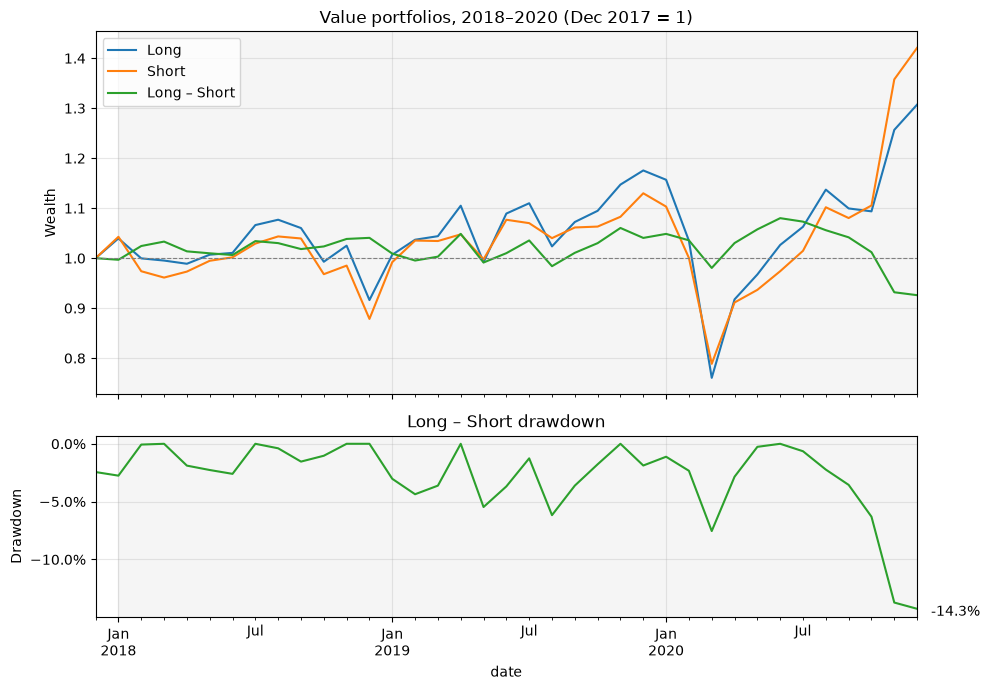

In [28]:
ls  = wealth.columns[-1]                 
win = slice('2017-12', '2020-12')

w_reb = wealth.loc[win] / wealth.loc[win].iloc[0]          
dd    = (wealth / wealth.cummax() - 1).loc[win]             

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

w_reb.plot(ax=ax1)
ax1.axhline(1, color='grey', lw=0.8, ls='--')
ax1.set(title='Value portfolios, 2018–2020 (Dec 2017 = 1)', ylabel='Wealth')

ax2.fill_between(dd.index, dd[ls], 0, color='C2', alpha=0.3)
dd[ls].plot(ax=ax2, color='C2')
ax2.set(title='Long – Short drawdown', ylabel='Drawdown')
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

t = dd[ls].idxmin()
ax2.annotate(f'{dd[ls].min():.1%}', xy=(t, dd[ls].min()),
             xytext=(10, -5), textcoords='offset points')

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp('2018-01-01'), pd.Timestamp('2020-12-31'),
               color='grey', alpha=0.08)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()